In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

# Do we think the same thing is happening in all of these countries?

This is a hypothetical dataset representing pesticide residues above a safety threshold vs. percentage of organic farms in different countries. How can we tell if trends are consistent across countries?

In [2]:
for file in Path('.').glob("*.csv"):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    coeff = np.polyfit(x, y, deg=1)
    corr = np.corrcoef(x, y)[0, 1]
    
    print(f"x_mean={x_mean:.3f}, y_mean={y_mean:.3f}, linear regression fr(x)={coeff[1]:.1f} {coeff[0]:.2f} x, r = {corr:.3f} ")

x_mean=54.261, y_mean=47.830, linear regression fr(x)=53.2 -0.10 x, r = -0.062 
x_mean=54.268, y_mean=47.836, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.269, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.266, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.267, y_mean=47.838, linear regression fr(x)=53.8 -0.11 x, r = -0.068 
x_mean=54.267, y_mean=47.840, linear regression fr(x)=53.3 -0.10 x, r = -0.063 
x_mean=54.263, y_mean=47.832, linear regression fr(x)=53.5 -0.10 x, r = -0.064 
x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.6 -0.11 x, r = -0.066 
x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.1 -0.10 x, r = -0.060 
x_mean=54.270, y_mean=47.837, linear regression fr(x)=53.9 -0.11 x, r = -0.069 
x_mean=54.269, y_mean=47.835, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.266, y_mean=47.835, linear regression fr(x)=53.4 -0.10 x, r = -0.064 
x_mean=54.267, y_mean=47.832, linear reg

## 1. Kennzahlen pro Land

Die Spalten der CSV-Dateien sind nur mit `x` und `y` beschriftet. Ich nehme an: `x` = Anteil Bio-Betriebe, `y` = Anteil Messstellen über dem Grenzwert (beide in %).

In [3]:
rows = []
for file in sorted(Path('.').glob("*.csv")):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    slope, intercept = np.polyfit(x, y, deg=1)
    r = np.corrcoef(x, y)[0, 1]
    n = len(df)
    rows.append({
        'Land': file.stem,
        'n': n,
        'x_mean': x.mean(),
        'y_mean': y.mean(),
        'x_sd': x.std(),
        'y_sd': y.std(),
        'Achsenabschnitt': intercept,
        'Steigung': slope,
        'r': r,
        'R2': r**2,
        't (Steigung)': r * np.sqrt(n - 2) / np.sqrt(1 - r**2),
    })

summary = pd.DataFrame(rows).set_index('Land')
summary.round(3)

,n,x_mean,y_mean,x_sd,y_sd,Achsenabschnitt,Steigung,r,R2,t (Steigung)
Land,,,,,,,,,,
Algerra,142,54.261,47.830,16.766,26.940,53.211,-0.099,-0.062,0.004,-0.732
Belmara,142,54.268,47.836,16.767,26.936,53.850,-0.111,-0.069,0.005,-0.818
Brunovia,142,54.269,47.831,16.769,26.936,53.809,-0.110,-0.069,0.005,-0.813
Cyrdania,142,54.266,47.831,16.769,26.939,53.813,-0.110,-0.069,0.005,-0.814
Elandia,142,54.267,47.838,16.760,26.930,53.797,-0.110,-0.068,0.005,-0.811
Ivoria,142,54.267,47.840,16.769,26.930,53.327,-0.101,-0.063,0.004,-0.746
Kaslovia,142,54.263,47.832,16.765,26.935,53.453,-0.104,-0.064,0.004,-0.764
Lazkova,142,54.260,47.840,16.770,26.930,53.554,-0.105,-0.066,0.004,-0.778
Marensia,142,54.260,47.840,16.768,26.930,53.098,-0.097,-0.060,0.004,-0.715


**Was die Zahlen zeigen:** Mittelwerte, Standardabweichungen, Regressionsgerade und Korrelation sind in allen Ländern praktisch gleich. Die Steigung liegt überall bei etwa −0.10, r bei etwa −0.06.

Auch dieser scheinbare Trend ist schwach: x erklärt weniger als 1 % der Varianz von y (R²), und |t| liegt in jedem Land unter dem kritischen Wert von rund 1.98 (df = 140, α = 0.05). Die Steigung ist also in keinem Land signifikant von null verschieden.

Nach den Kennzahlen allein wären alle Länder gleich. Ob das stimmt, zeigt erst der Blick auf die Daten.

## 2. Die Daten ansehen

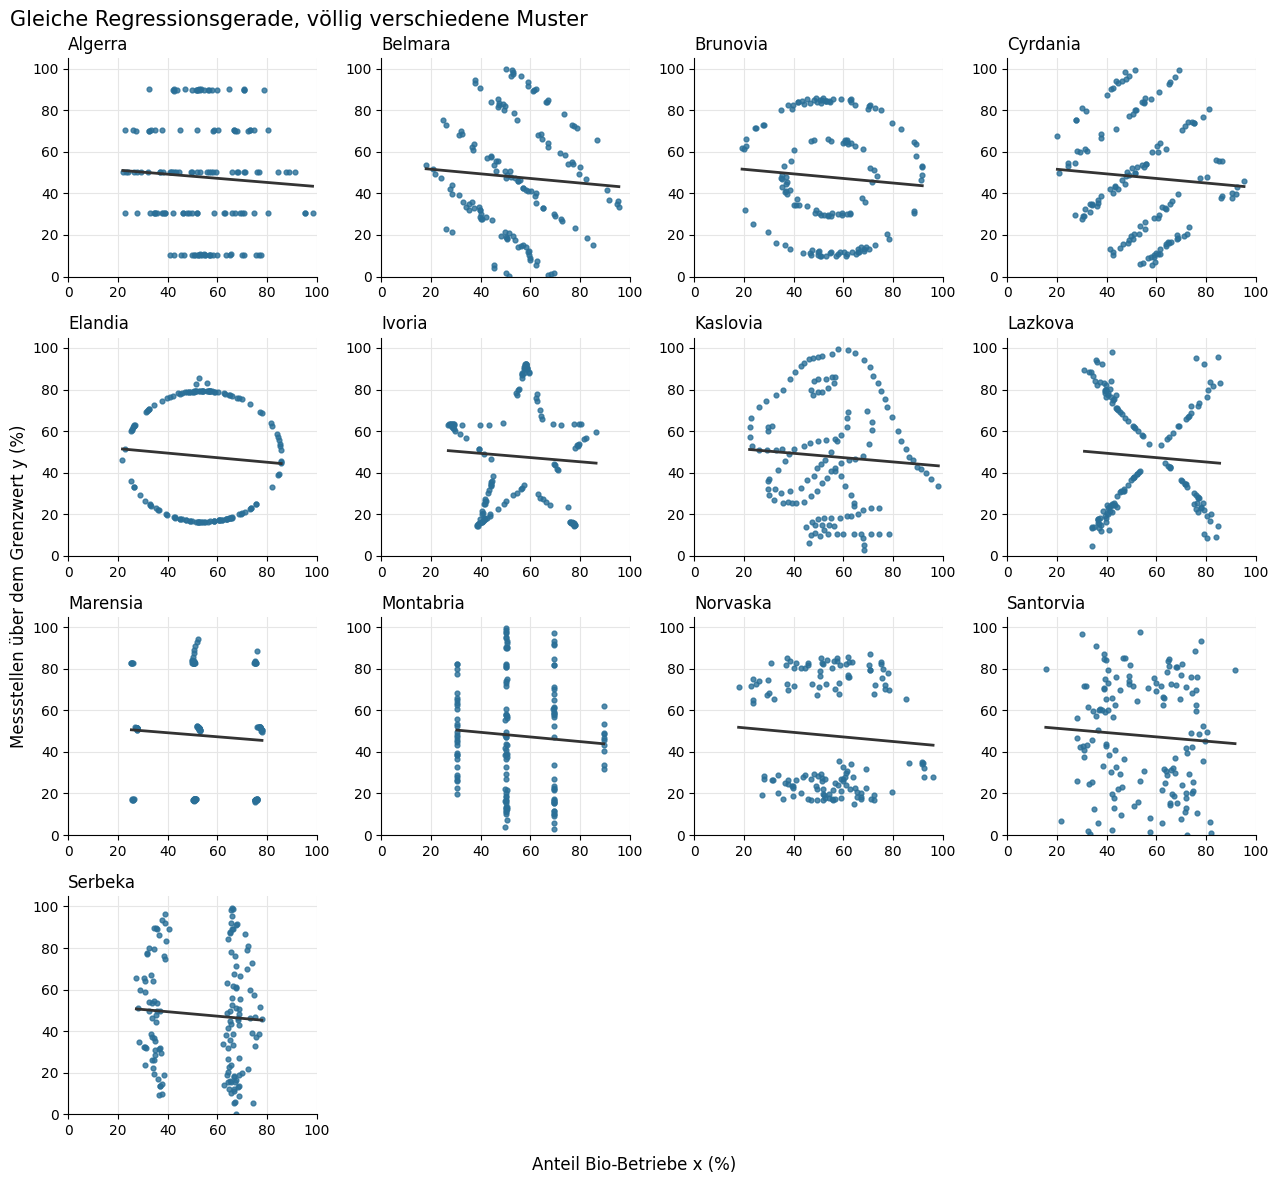

In [4]:
files = sorted(Path('.').glob("*.csv"))
fig, axes = plt.subplots(4, 4, figsize=(13, 12), sharex=True, sharey=True)

for ax in axes.flat[len(files):]:
    ax.set_visible(False)

for ax, file in zip(axes.flat, files):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    slope, intercept = np.polyfit(x, y, deg=1)
    x_line = np.array([x.min(), x.max()])

    ax.scatter(x, y, s=12, color='#2a6f97', alpha=0.8)
    ax.plot(x_line, intercept + slope * x_line, color='#333333', linewidth=2)
    ax.set_title(file.stem, loc='left')
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 105)
    ax.grid(color='#e6e6e6', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelbottom=True, labelleft=True)

fig.supxlabel('Anteil Bio-Betriebe x (%)')
fig.supylabel('Messstellen über dem Grenzwert y (%)')
fig.suptitle('Gleiche Regressionsgerade, völlig verschiedene Muster', x=0.02, ha='left', fontsize=15)
fig.tight_layout()
plt.show()

**Was die Plots zeigen:** Jedes Land hat ein anderes Muster.

| Land | Muster |
|---|---|
| Algerra | horizontale Linien |
| Belmara | parallele, fallende Linien |
| Brunovia | zwei ineinanderliegende Ringe |
| Cyrdania | parallele, steigende Linien |
| Elandia | ein einzelnes Oval |
| Ivoria | Stern |
| Kaslovia | Dinosaurier |
| Lazkova | X-Form |
| Marensia | wenige enge Punktgruppen |
| Montabria | vertikale Linien |
| Norvaska | zwei horizontale Bänder |
| Santorvia | Streuung ohne klare Struktur |
| Serbeka | zwei vertikale Bänder |

Innerhalb der Muster widerspricht die lokale Richtung teils der Gesamtgeraden: In Cyrdania steigt y innerhalb jeder Linie mit x, obwohl die Gerade fällt. In Algerra bleibt y innerhalb jeder Linie konstant.

## 3. Antwort: Ist der Zusammenhang überall gleich?

**Nein.** Die Länder teilen dieselben Kennzahlen, aber nicht denselben Zusammenhang zwischen Bio-Anteil und Pestizidrückständen.

- **Kennzahlen:** Fast identisch, mit einem schwachen, nicht signifikanten negativen linearen Trend.
- **Plots:** Das Muster unterscheidet sich von Land zu Land. Eine Gerade beschreibt keines davon sinnvoll.
- **Folgerung:** Aus Kennzahlen allein lässt sich nicht schliessen, dass in zwei Datensätzen dasselbe passiert. Deshalb gehört vor jede Zusammenfassung ein Plot der Rohdaten.

**Grenzen:** Die Daten sind fiktiv, und die Muster sehen konstruiert aus (Stern, Dinosaurier). Reale Ursachen lassen sich daraus nicht ableiten. Auch bei echten Daten würde eine Korrelation allein keine Kausalität belegen.